# Research Question 4: Data Augmentation

## 6.1 How sensitive does the model respond to certain data augmentations?

We investigate whether data augmentations change the model's predictions, changing the images contrast, gamma, blur and resolution.

In [ ]:
from IPython.utils.capture import capture_output
from IPython.display import display

with capture_output() as captured:
    %run neighbor_analysis.ipynb

In [5]:
images = np.stack([x["img"] for x in XRAY_DATASET])

We start by changing a certain image that might be of interest with regards to

* Contrast
* Gamma
* Blur
* Resolution

Questions include, selecting an image that was labelled TP - Which augmentation in which intensity will make the model potentially fail in its prediction? Or vice versa, can we adjust the image that was classified a FP in a way that makes the model decrease its prediction score?

For example, the model predicts a score of **0.924** for **Image 383** and label **Pneumothorax**, creating a **FP**. While changing the contrast still leads to predictions over 0.5 (even with the strongest augmentation factor available in this widget), blur and resolution changes highly decrease the prediction.
We try this with several other images and the same label. Can we observe a pattern that might be worth investigating?

In [ ]:
display(create_augmentation_widget(images, ["contrast", "gamma", "blur", "resolution"]))

Even though investigating certain images might be interesting and serve as an intuition, we cannot generalize our findings from individual cases. Thus, we manipulate the whole Subset. As this calculation is computationally expensive, we chose a relatively high intensity of distortion, changing and caching our whole Subset four times in total.

In [8]:
augmentation_methods = [None, "contrast", "gamma", "blur", "resolution"]
datasets = {method or "Original": AugmentedXRayDataset(images, method=method, strength=0.6) for method in augmentation_methods}

In [9]:
comparison = compare_augmentations(datasets, "S-UMAP", visualization_functions, visualization_names, XRAY_LABELS_LIST, DATASET_LABEL_INDICES_MAP)

Processing: Original
Processing: contrast
Processing: gamma
Processing: blur
Processing: resolution


We try to answer how much the prediction of the model changes with comparing the prediction scores from the original images and augmented images.

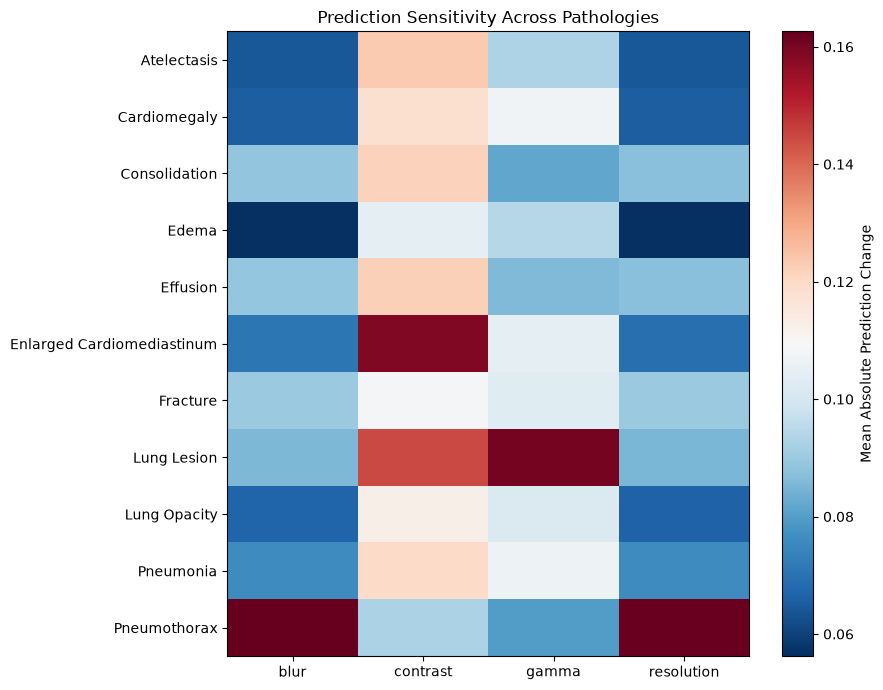

In [14]:
score_comparison = compare_prediction_scores(comparison, DATASET_PATHOLOGIES, DENSENET121_RES244_CHEX_MODEL.pathologies)
plot_prediction_sensitivity(score_comparison)

Using a threshold of 0.7, we don't look at the raw prediction scores but the labelling of our manipulated data. Has the model's overall precision increased or decreased?

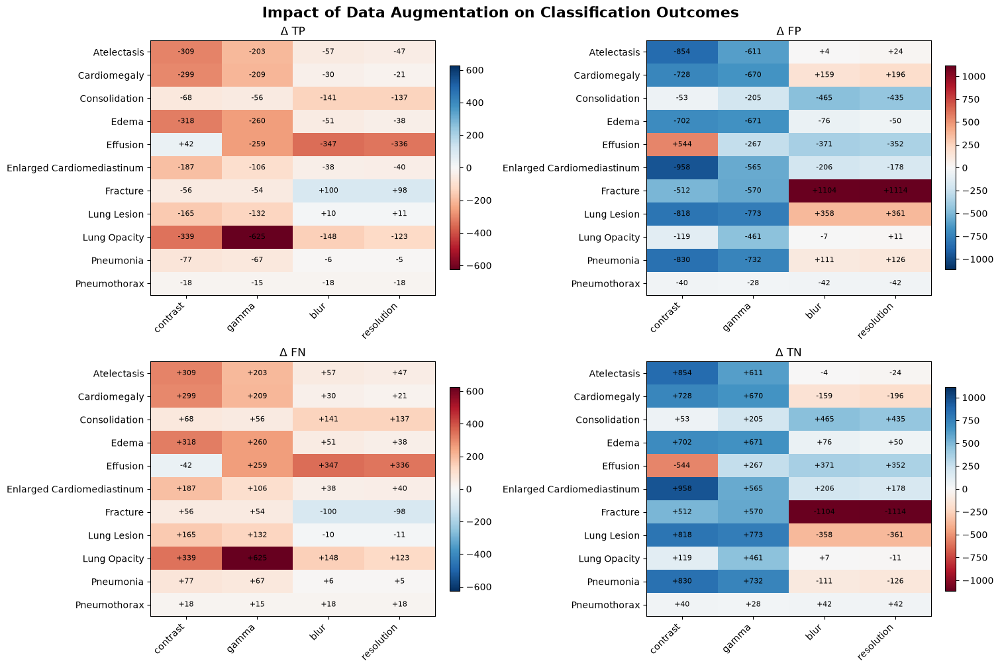

In [20]:
counts, delta = calculate_augmentation_changes(comparison, XRAY_LABELS_LIST, dataset_label_indices_map=DATASET_LABEL_INDICES_MAP)
plot_augmentation_heatmaps(delta)

### Findings

Generally contrast and gamma augmentations lead to more negative predictions (TN + FN) across most diseases, while augmentations with blur and resolution have varying effects depending on the disease.
Increase Gamma Correction leads the model to predict Lung Opacity less often. 
Blur and resolution reduction substantially increase false-positive Fracture predictions, despite improving sensitivity.

Finally, we compare AUC and PR for each pathology. Even though classification drastically change with our augmented datasets, ROC and PR curves appear similar, indicating that the model still has discriminative ability despite changes in prediction scores.

In [12]:
fig = plot_augmentation_dashboard(
    comparison,
    XRAY_LABELS_LIST,
    DATASET_LABEL_INDICES_MAP,
    delta)